# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [1]:
# Import the packages used in Lab 07.
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

# Display species counts.
amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


In [2]:
target_species = "Ambystoma maculatum"

# Select your species and apply the uncertainty filter.\
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

# Store the result as presence and print its record count.
print("Number of records:", len(presence))

Number of records: 894


**Why did you choose this species?**  This species has a fair number of observations and I really enjoy working with salamander data because it opens itself to analyses about precipitation and temperature.

## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [3]:
# Create climate_variables and display these columns at your species' records.
climate_variables = ["bio_1", "bio_19"]
presence[climate_variables].head()

,bio_1,bio_19
221,7.011833,357.0
366,3.071667,205.0
428,7.011833,357.0
609,6.460667,295.0
639,3.205833,204.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [4]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()


,x,y,bio_1,bio_19
146,-69.229167,47.437500,2.610167,231.0
147,-69.187500,47.437500,2.620167,228.0
148,-69.145833,47.437500,2.786333,222.0
246,-69.270833,47.395833,2.161333,237.0
247,-69.229167,47.395833,2.441500,231.0


In [5]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()


Usable presence records: 894


,bio_1,bio_19,observed
221,7.011833,357.0,1
366,3.071667,205.0,1
428,7.011833,357.0,1
609,6.460667,295.0,1
639,3.205833,204.0,1


In [6]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    894
0    894
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [7]:
# Set features to bio_1 only.
features = ["bio_1"]

# Define X and y, following Lab 07.
X = model_data[features]
y = model_data["observed"]

X.head()

,bio_1
0,7.011833
1,3.071667
2,7.011833
3,6.460667
4,3.205833


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [8]:
# Split model_data into train_data and test_data.
# Define X_train, X_test, y_train, and y_test using features and observed.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

# Create model and fit it to the training data.
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)

# Predict suitability for X_test.
test_prediction = model.predict(X_test)

## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.23


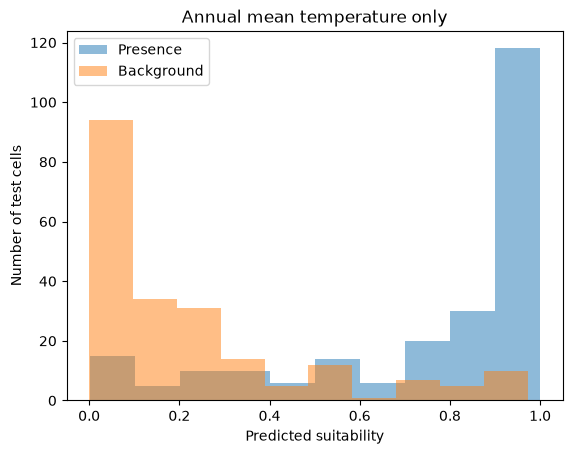

In [9]:
# Calculate and print bio1_error.
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))
# Plot the predicted score distributions for the two test labels.
plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model?

## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [10]:
# Select the three predictor columns from the existing training and test tables.
features = ["bio_19", "bio_18", "bio_11"] # precip of coldest quarter, precip of warmest quarter, mean temp of coldest quarter

# need to re-create model_data with these columns
climate_variables = ["bio_19", "bio_18", "bio_11"]
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0
model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()

# Fit three_variable_model and predict the same withheld cells.
X = model_data[features]
y = model_data["observed"]

# Define X_train, X_test, y_train, and y_test using features and observed.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

# Create model and fit it to the training data.
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)

# Predict suitability for X_test.
test_prediction = model.predict(X_test)

# Calculate three_variable_error and print it beside bio1_error.
three_variable_error = mean_absolute_error(y_test, test_prediction)
print("Three variable MAE:", round(three_variable_error, 3))

Three variable MAE: 0.192


**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically. The error was very slightly improved (0.04 lower). I think they are relevant biologically because they affect availability of vernal pools during the breeding period, but its likely that not all three of the variables I chose should be included in the model because they may be correlated.

## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


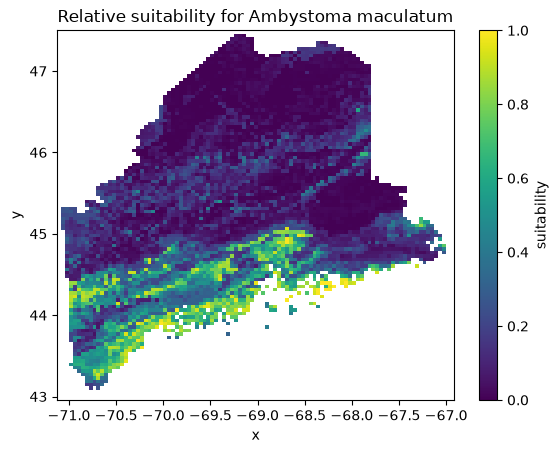

In [11]:
# Update X to include all three predictors.
X = model_data[features]

# Fit final_model with the same forest settings.
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)

# Add grid["suitability"], convert it to a raster named suitability, and plot it.
grid["suitability"] = final_model.predict(grid[features])
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()

**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence? Most of southern Maine received high scores, particularly along the coast. These should be described as relative suitability rather than probability of occurrence because the model only takes into account the three climatic predictor variables. There are several other variables not considered by the model, such as habitat suitability and detection parameters.

## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


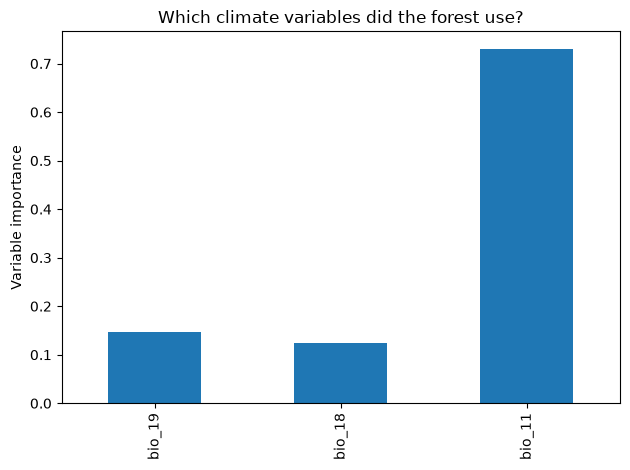

In [12]:
# Make and label a variable-importance plot.
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()

**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause. The most important variable in this model was bio_11 which represents the mean temperature during the coldest quarter. I'm curious what the coefficient of this variable is and whether colder temperatures were better or worse for suitability (although I infer that colder temperatures were worse based on the map, which shows higher suitability in southern parts of the state). This is a pattern that should be explored, but it does not establish an ecological cause because we cannot determine from the model whether colder temperatures lead to habitat suitability, or whether temperature covaries with other factors that cause 

## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [13]:
# Assign EPSG:4326 and save the suitability raster.
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Assignment07_suitability.tif")

## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model? Yes...

In [14]:
# Run the full analysis again but this time include all 19 bioclim variables
# Select the three predictor columns from the existing training and test tables.
climate_variables = ["bio_" + str(number) for number in range(1, 20)]

# need to re-create model_data with these columns
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0
model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()

# Fit model and predict the same withheld cells.
features = climate_variables
X = model_data[features]
y = model_data["observed"]

# Define X_train, X_test, y_train, and y_test using features and observed.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

# Create model and fit it to the training data.
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)

# Predict suitability for X_test.
test_prediction = model.predict(X_test)

# Calculate three_variable_error and print it beside bio1_error.
full_model_error = mean_absolute_error(y_test, test_prediction)
print("Full model MAE:", round(full_model_error, 3))

Full model MAE: 0.196


## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve? This week's random forest didn't define a model formula like the hand-build temperature did, but rather it tested several temperatures from the data and used the likelihood of 1s and 0s for certain temperatures to evaluate suitability.
2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error? Using three predictors very slightly decreased error, but I have a hunch that eliminating one of the predictors would have led to the same amount of error. I would expect more predictors to sometimes lead to more test error due to model overfitting.
3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location? If the temperature of a test cell matches exactly to a temperature to a training cell, the model will know with certainty whether a presence is likely in the cell, rather than inferring from slightly different temperature values.
4. Name one habitat variable or sampling issue missing from your model. How might it affect the map? This model was missing habitat data such as proximity to freshwater bodies, which are necessary for this species during certain times of year. 

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
